# Building an optimal portfolio system

1) Forecast (currently vry simple OLS)
2) Risk model (factor model)
3) Cost model (currently with only spread)
4) Optimization framework (with scaling and factor sparsity for numerical stability)

### Issues
- Covariance matrix currently still in standardized returns. Need to change units by adding the garch modeled term.

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
with open("../top_100_universe.txt", "r") as f:
    ACTIVE_SET = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty", "paired_qty", "ref_price"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)),
            pl.col("symbol").is_in(ACTIVE_SET))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(13,30), pl.time(21,0)),
            pl.col("symbol").is_in(ACTIVE_SET))
    .with_columns(pl.col('ts_event').dt.convert_time_zone("America/New_York"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .with_columns(pl.col("symbol").cast(pl.Categorical))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11,
            pl.col("symbol").is_in(ACTIVE_SET))
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).shift(1).over("symbol").alias("ADV")
    )
    .drop("day_volume")
    .collect(engine="streaming")
)

# Causal per-(date, symbol) daily volatility: EWMA of squared daily returns, SHIFTED 1 day (uses only
# past info) -- same causal recipe as ADV.  sigma_{i,d} = sqrt( EWMA(day_ret^2) )_{d-1}, day close = last mid.
daily_vol = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"),
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,0)))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(pl.col("mid").last().alias("close"))
    .sort(["date", "symbol"])
    .with_columns(pl.col("close").pct_change().over("symbol").alias("day_ret"))
    .with_columns(
        pl.col("day_ret").pow(2).ewm_mean(span=10, adjust=True).shift(1).over("symbol").sqrt().alias("vol")
    )
    .select(["date", "symbol", "vol"])
    .collect(engine="streaming")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
    .collect(engine="streaming")
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid")
    )
    .with_columns(
        ((pl.col("ask_px_00") - pl.col("bid_px_00")) / pl.col("mid")).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,49,55), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["mid"]).last(),
        pl.col(["spread_return"]).mean()
    )
    .rename({"mid":"entry_price"})
    .collect(engine="streaming")
)

recent_return = (
    df_trades
    .with_columns(pl.col("ts_event").dt.date().alias("date"),
                  ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,40,00), pl.time(15,49,59)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        (pl.col("mid").last() - pl.col("mid").first())/pl.col("mid").first()
    )
    .rename({"mid":"recent_return"})
    .collect(engine="streaming")
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,50,00), pl.time(15,50,5)))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["ts_event", "side", "total_imbalance_qty", "paired_qty", "ref_price"]).first()
    )
    .collect(engine="streaming")
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .join(daily_vol, on=["date", "symbol"])
    .join(recent_return, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .with_columns(
        (pl.col("total_imbalance_qty") * pl.col("ref_price")).alias("dollar_imbalance"),
        (pl.col("paired_qty") * pl.col("ref_price")).alias("paired_dollars"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
        ).alias("sign"),
    )
    .with_columns(
        (
            pl.col("sign") * pl.col("dollar_imbalance")
        ).alias("signed_dollar_imbalance")
    )
    .drop(["total_imbalance_qty"])
    .drop_nulls()
    .with_columns(
        (
            (pl.col("paired_dollars") / pl.col("ADV"))
        ).alias("auction_dollar_volume_ratio"),
        (
            pl.when(pl.col("paired_dollars") != 0).then(pl.col("signed_dollar_imbalance") / pl.col("paired_dollars"))
            .otherwise(0)
        ).alias("net_signed_imb"),
        (
            (pl.col("auction_price") - pl.col("entry_price")) / pl.col("entry_price")
        ).alias("return_to_close")
    )
    .with_columns(
        (pl.col("return_to_close") - pl.col("return_to_close").mean().over("date")).alias("close_return_xm"),
        (pl.col("recent_return") - pl.col("recent_return").mean().over("date")).alias("recent_return_xm"),
        (pl.col("auction_dollar_volume_ratio") - pl.col("auction_dollar_volume_ratio").mean().over("date")).alias("auction_dollar_volume_ratio_xm"),
        (
            ((pl.col("net_signed_imb").rank().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))) 
             / (pl.col("net_signed_imb").rank().max().over(pl.col("date")) - pl.col("net_signed_imb").rank().min().over(pl.col("date"))))
             * 2 - 1
        ).alias("norm_rank_net_imb"),
    )
    .with_columns(
        (pl.col("norm_rank_net_imb") * pl.col("recent_return_xm")).alias("norm_rank_net_x_recent_xm"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("norm_rank_net_imb")).alias("norm_rank_net_x_auction"),
        (pl.col("auction_dollar_volume_ratio_xm") * pl.col("recent_return_xm")).alias("auction_x_recent_xm")
    )
)

test_data = data.filter(pl.col("date").is_between(pl.date(2026,1,1), pl.date(2026,6,11), closed="both"))
test_data

date,symbol,ts_event,side,paired_qty,ref_price,entry_price,spread_return,auction_price,ADV,vol,recent_return,dollar_imbalance,paired_dollars,sign,signed_dollar_imbalance,auction_dollar_volume_ratio,net_signed_imb,return_to_close,close_return_xm,recent_return_xm,auction_dollar_volume_ratio_xm,norm_rank_net_imb,norm_rank_net_x_recent_xm,norm_rank_net_x_auction,auction_x_recent_xm
date,cat,"datetime[ns, America/New_York]",str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,i32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2026-01-02,"""AAPL""",2026-01-02 15:50:00.094608097 EST,"""B""",2428652,270.51,270.48,0.000043,271.01,1.9679e9,0.005372,-0.000259,1.3830e8,6.5697e8,1,1.3830e8,0.333839,0.210516,0.001959,0.001947,0.001372,-0.05823,0.342857,0.00047,-0.019964,-0.00008
2026-01-02,"""ABNB""",2026-01-02 15:50:00.002159268 EST,"""B""",182011,133.06,133.055,0.000075,133.01,9.2872e7,0.008585,-0.000038,1.5611e7,2.4218e7,1,1.5611e7,0.260772,0.644598,-0.000338,-0.000351,0.001593,-0.131296,0.8,0.001275,-0.105037,-0.000209
2026-01-02,"""ADBE""",2026-01-02 15:50:00.126788139 EST,"""B""",150587,334.32,334.27,0.000279,333.3,2.2710e8,0.00908,0.000329,7.3360e6,5.0344e7,1,7.3360e6,0.221683,0.145716,-0.002902,-0.002915,0.00196,-0.170386,0.228571,0.000448,-0.038945,-0.000334
2026-01-02,"""ADI""",2026-01-02 15:50:00.053777257 EST,"""A""",306758,274.15,274.32,0.000583,273.74,1.2113e8,0.009605,-0.00318,6.4508e7,8.4098e7,-1,-6.4508e7,0.694274,-0.767061,-0.002114,-0.002127,-0.001549,0.302205,-0.857143,0.001328,-0.259033,-0.000468
2026-01-02,"""ADP""",2026-01-02 15:50:00.126279917 EST,"""A""",111653,252.64,252.7,0.000475,252.88,8.3750e7,0.007921,-0.001087,2.1980e7,2.8208e7,-1,-2.1980e7,0.336813,-0.779218,0.000712,0.0007,0.000544,-0.055256,-0.885714,-0.000482,0.048941,-0.00003
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""UAL""",2026-06-10 15:50:00.039975988 EDT,"""B""",459492,102.84,102.855,0.000318,102.78,1.0594e8,0.029836,-0.000097,2.9506e6,4.7254e7,1,2.9506e6,0.446035,0.062441,-0.000729,0.001621,0.00137,0.065524,0.529412,0.000725,0.034689,0.00009
2026-06-10,"""ULTA""",2026-06-10 15:50:00.093100557 EDT,"""B""",19855,470.25,470.31,0.000247,470.75,9.8677e7,0.02367,-0.000234,2.1693e6,9.3368e6,1,2.1693e6,0.09462,0.232334,0.000936,0.003286,0.001233,-0.285891,0.858824,0.001059,-0.24553,-0.000353
2026-06-10,"""WDAY""",2026-06-10 15:50:00.114329290 EDT,"""A""",262562,137.6,137.7,0.000266,137.47,1.7716e8,0.040454,-0.00351,5616556.8,3.6129e7,-1,-5.6166e6,0.203937,-0.15546,-0.00167,0.00068,-0.002043,-0.176574,-0.388235,0.000793,0.068552,0.000361


In [4]:
[s for s in ACTIVE_SET if s not in test_data.select("symbol").unique().to_numpy()]

['CRWV', 'TEM', 'RGTI', 'EXE', 'ITCI']

## Daily MVO Optimizer

In [5]:
import cvxpy as cp
import scipy

class ForecastModel:
    def __init__(self, universe, model, features):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.model = model
        self.features = features

    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        alpha = np.zeros(len(self.universe))
        preds = self.model.predict(day_df[self.features].to_numpy()).ravel()  # scaled inside pipeline
        for symbol, p in zip(day_df["symbol"], preds):
            alpha[self.sym_idx_map[symbol]] = p
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}

    def get_cost(self, day_df: pl.DataFrame, commission: float) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread, comm_rate in zip(day_df["symbol"], day_df["spread_return"], commission / day_df['entry_price']):
            cost[self.sym_idx_map[symbol]] = (spread * 0.5) + (2 * comm_rate)
        return cost

class ImpactModel:
    """Square-root market impact (Almgren/BARRA form):
        price impact  I_i    = gamma * sigma_i * sqrt(Q$_i / ADV$_i)           (a return; gamma ~ O(0..1))
        dollar cost   cost_i = gamma * sigma_i * |Q$_i|^{3/2} / sqrt(ADV$_i)   (= I_i * |Q$_i|)
    gamma is ONE scalar shared across names (swept separately).  sigma_i (daily return vol) AND ADV$ (daily
    $volume) are BOTH CAUSAL per-(name, date) columns on test_data (EWMA, shifted 1 day) -> only past info.
    Supplies the per-day, per-name impact coefficient  sigma_{i,d} / sqrt(ADV$_{i,d})  (ACTIVE_SET order),
    used by BOTH the optimizer objective and the PnL accounting so expected/realized impact stay consistent."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}

    def get_impact_coeff(self, day_df: pl.DataFrame) -> np.ndarray:
        v = np.zeros(len(self.universe))
        for symbol, vol, adv in zip(day_df["symbol"], day_df["vol"], day_df["ADV"]):
            if vol is not None and adv is not None and vol > 0 and adv > 0:
                v[self.sym_idx_map[symbol]] = vol / np.sqrt(adv)
        # names with no vol/ADV that day -> charge them like the highest-coeff present name (never "free" to trade)
        if (v == 0).any() and (v > 0).any():
            v[v == 0] = v[v > 0].max()
        return v

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        self.scale = None

    def set_problem(self, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, scale = None):
        # -- Variables / parameters --
        self.x     = cp.Variable(self.N)
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        self.impact_coeff = cp.Parameter(self.N, nonneg=True)   # per-day sigma_i/sqrt(ADV$_i), ACTIVE_SET order
        self.gamma = float(gam)                                 # scalar square-root-impact coefficient (~O(0..1))
        self.Sigma_r = cp.Constant(Sigma_r)
        self.L = cp.Constant(Loadings)
        self.eps_diag = eps_diag
        self.scale = float(vol_cap if scale is None else scale)
        self.D = np.diag(eps_diag)
        self.lamdba = cp.Constant(lam)

        # -- Objective --
        # Impact is a 3/2-power dollar cost  gamma * sigma_i * |Q$_i|^{3/2} / sqrt(ADV$_i).  With Q$ = scale*x and
        # the objective in per-scale units it enters as  gamma * sqrt(scale) * sum_i (sigma_i/sqrt(ADV$_i)) * |x_i|^{3/2}.
        # The per-name, per-day coefficient sigma_i/sqrt(ADV$_i) is the impact_coeff parameter (both terms causal).
        self.objective = cp.Maximize(
            self.alpha @ self.x
            - (self.lamdba * self.scale / 2) * ( cp.quad_form(self.L @ self.x, Sigma_f) + cp.quad_form(self.x, self.D) )
            - (self.cost / 2) @ cp.abs(self.x)
            - self.gamma * (self.scale ** 0.5) * cp.sum(cp.multiply(self.impact_coeff, cp.power(cp.abs(self.x), 1.5)))
        )

        # -- Constraints --
        Sigma_f_sqrt = scipy.linalg.sqrtm(Sigma_f).real
        D_sqrt  = np.sqrt(self.eps_diag)
        quad_risk = cp.norm(cp.hstack([Sigma_f_sqrt @ self.L @ self.x, cp.multiply(D_sqrt, self.x)]), 2)   # = √(xᵀΣx) but numerically sparse with factors
        self.constraints = [
            # cp.sum(self.x) == 0,                       # dollar neutrality
            quad_risk <= vol_cap / self.scale,           # Expected volatility √(xᵀΣx) ≤ target daily dollar volatility, with scale factor
        ]
        # Three factor-neutrality
        self.constraints += [self.x @ Loadings[i,:] == 0 for i in range(0,2)]
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost, impact_coeff) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.impact_coeff.value = impact_coeff
        self.problem.solve(solver=cp.CLARABEL)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        # -- Dollar denominated optimal portfolio
        return self.x.value * self.scale

## Parallelized Daily Optimization

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

### Loading Forecast and Risk Models

In [6]:
import joblib

# Load the model back into memory
loaded_model = joblib.load("../forecast/forecast_pipe.joblib")
features = [
        "norm_rank_net_imb", 
        "recent_return_xm",
        "auction_dollar_volume_ratio_xm", 
        "norm_rank_net_x_recent_xm",
        "norm_rank_net_x_auction",
    ]
# --- Now using returns units versions with sample volatilities over training window---
L        = np.load("../covariance/loadings_return.npy")          # was loadings.npy
EPS_DIAG = np.load("../covariance/idiosyncratic_diag_return.npy") # was idiosyncratic_diag_vec.npy
SIGMA_F  = np.load("../covariance/factor_cov_matrix.npy")         # unchanged
SIGMA_R  = np.load("../covariance/cov_matrix_return.npy")         # was cov_matrix.npy

f_model = ForecastModel(ACTIVE_SET, model=loaded_model, features=features)
c_model = CostModel(ACTIVE_SET)
i_model = ImpactModel(ACTIVE_SET)

### Hyperparams and Backtesting

In [ ]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / i_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed
import warnings

N_JOBS = max(1, os.cpu_count() - 2)
COMMISSION_PER_SHARE = 0.0035
LAMBDA = 5e-5                            # Risk aversion per dollar, ~OOM of 1 / (intended capital).
DAILY_DOLLAR_VOL_CAP = 5e3
IMPACT_GAMMA = 0.5                       # square-root impact coefficient: I = gamma*sqrt(Q$/ADV$), gamma ~ O(0..1)

def _solve_chunk(symbols, Sigma_r, Sigma_f, Loadings, eps_diag, lam, gam, vol_cap, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    warnings.filterwarnings("ignore", message="Solution may be inaccurate")
    opt = Optimizer(symbols)
    opt.set_problem(Sigma_r=Sigma_r, Sigma_f=Sigma_f, Loadings=Loadings,
                    eps_diag=eps_diag, lam=lam, gam=gam, vol_cap=vol_cap)        # compile once per worker, not per day
    return [(date, opt.solve(alpha, cost, impact_coeff)) for date, alpha, cost, impact_coeff in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost, impact_coeff = sigma_i/sqrt(ADV$_i)) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = test_data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day, COMMISSION_PER_SHARE), i_model.get_impact_coeff(day))
    for d in all_dates
    for day in [test_data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, LAMBDA, IMPACT_GAMMA, DAILY_DOLLAR_VOL_CAP, chunk) for chunk in chunks
)

weights = {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

solved 110 days across 12 workers


### Plotting / Accounting

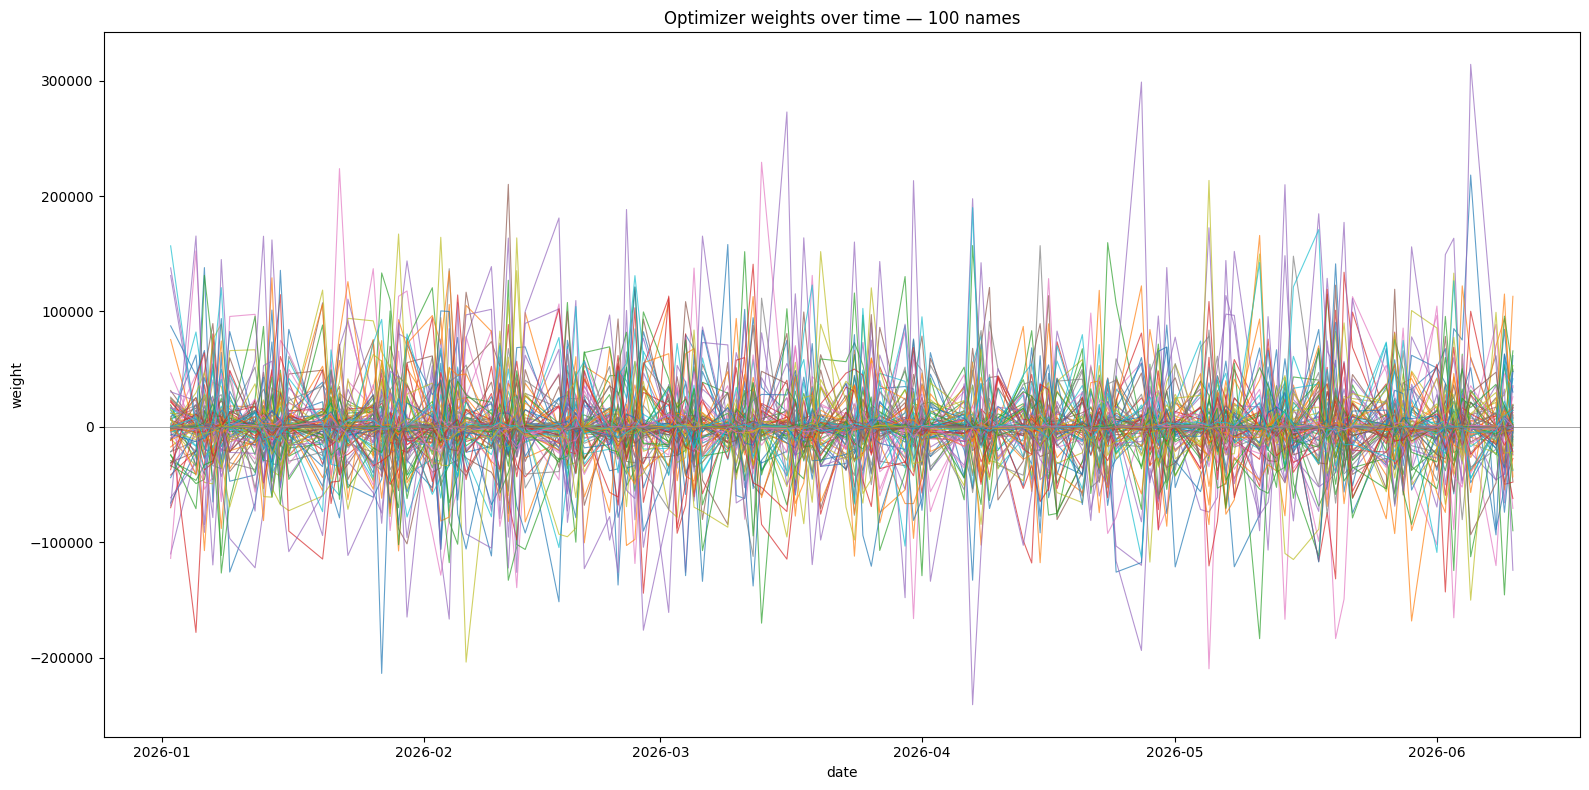

In [19]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

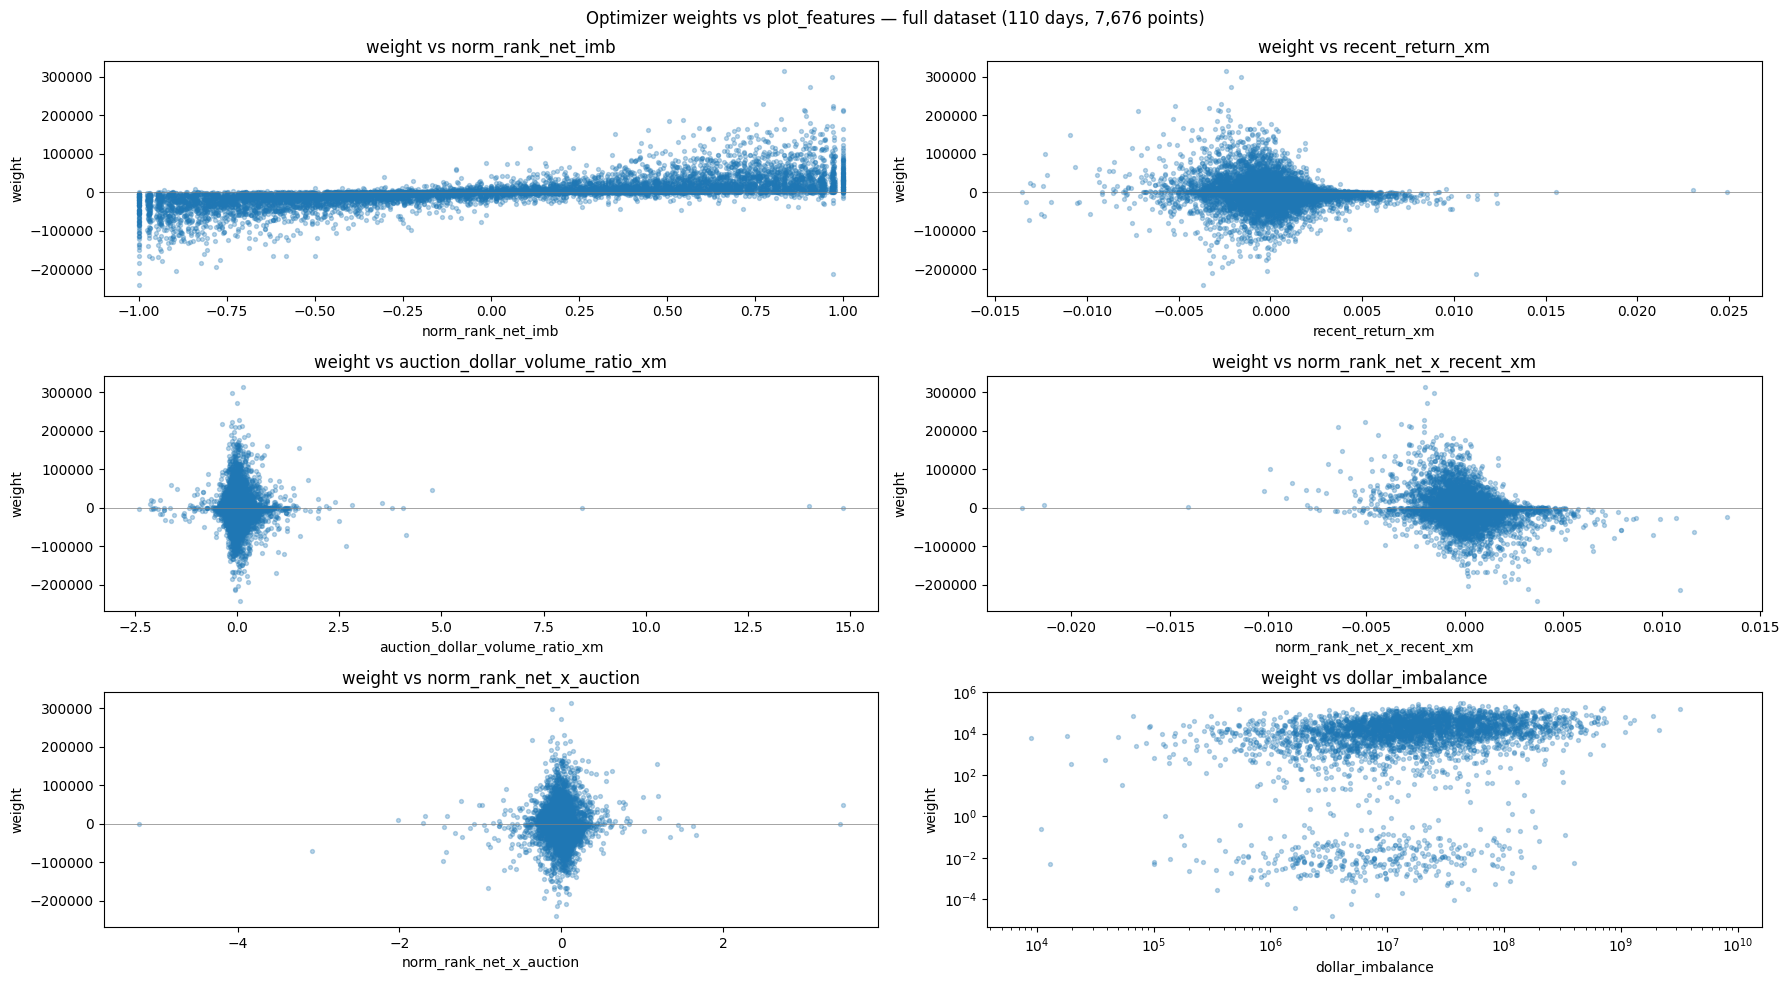

In [20]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = test_data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear
plot_features = features + ["dollar_imbalance"]

fig, axes = plt.subplots(3, 2, figsize=(18, 10))
for ax, feat in zip(axes.flat, plot_features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
        ax.set_yscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs plot_features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

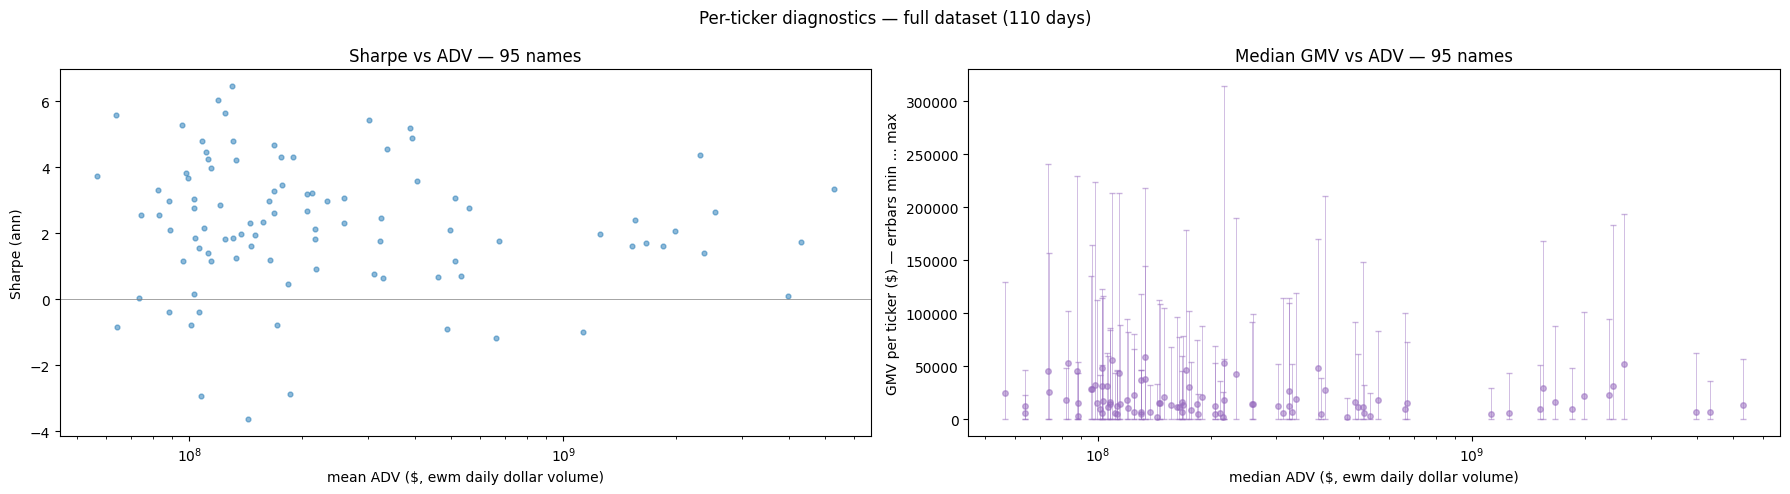

In [21]:
# Per-ticker scatters over the FULL dataset: Sharpe vs ADV, and mean GMV vs ADV.
# Rebuilds per-name daily net PnL with the SAME cost model as the PnL cell below,
# then collapses to one point per ticker:
#   - Sharpe_i  = mean_t(net_pnl_i,t) / std_t(net_pnl_i,t) * sqrt(252)   (zero-position days included)
#   - GMV_i,t   = |$pos_i,t|  -> mean per ticker, with bars spanning its min..max
#   - ADV_i     = mean of the day's ewm daily dollar volume for that name
ANN = 252

pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

name_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate")
    )
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")
         - pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("net_pnl_name"),
        pl.col("dollar_pos").abs().alias("gmv_name"),
    )
)

per_name = (
    name_daily
    .group_by("symbol")
    .agg(
        (pl.col("net_pnl_name").mean() / pl.col("net_pnl_name").std(ddof=1) * np.sqrt(ANN)).alias("sharpe"),
        pl.col("ADV").mean().alias("adv_mean"),
        pl.col("gmv_name").mean().alias("gmv_mean"),
        pl.col("gmv_name").median().alias("gmv_median"),
        pl.col("gmv_name").min().alias("gmv_min"),
        pl.col("gmv_name").max().alias("gmv_max"),
        pl.len().alias("n_days"),
    )
    .filter((pl.col("n_days") > 1) & pl.col("sharpe").is_finite())
    .sort("adv_mean")
)

adv      = per_name["adv_mean"].to_numpy()
sharpe_n = per_name["sharpe"].to_numpy()
gmv_median = per_name["gmv_median"].to_numpy()
gmv_lo   = gmv_median - per_name["gmv_min"].to_numpy()   # bar down to min (>= 0)
gmv_hi   = per_name["gmv_max"].to_numpy() - gmv_median   # bar up to max   (>= 0)

fig, (axS, axG) = plt.subplots(1, 2, figsize=(18, 5))

axS.scatter(adv, sharpe_n, alpha=0.5, s=12)
axS.axhline(0, color="grey", lw=0.5)
axS.set_xscale("log")
axS.set_xlabel("mean ADV ($, ewm daily dollar volume)")
axS.set_ylabel("Sharpe (ann)")
axS.set_title(f"Sharpe vs ADV — {len(per_name)} names")

axG.errorbar(adv, gmv_median, yerr=[gmv_lo, gmv_hi], fmt="o", ms=4, alpha=0.5,
             elinewidth=0.6, capsize=2, color="tab:purple")
axG.set_xscale("log")
# axG.set_yscale("log")
axG.set_xlabel("median ADV ($, ewm daily dollar volume)")
axG.set_ylabel("GMV per ticker ($) — errbars min ... max")
axG.set_title(f"Median GMV vs ADV — {len(per_name)} names")

fig.suptitle(f"Per-ticker diagnostics — full dataset ({len(weights)} days)")
fig.tight_layout()
plt.show()

Days traded:        110
Mean GMV:           $1,622,377
Median GMV:         $1,602,883
Max GMV:            $2,529,060  (1.6x mean GMV)
Gross PnL:          $142,713
Total cost:         $34,529
Total impact:       $26,870
Total net PnL:      $81,314
Max drawdown:       $-4,312.6
Sharpe (ann):       9.76
Daily hit rate:     84.5%


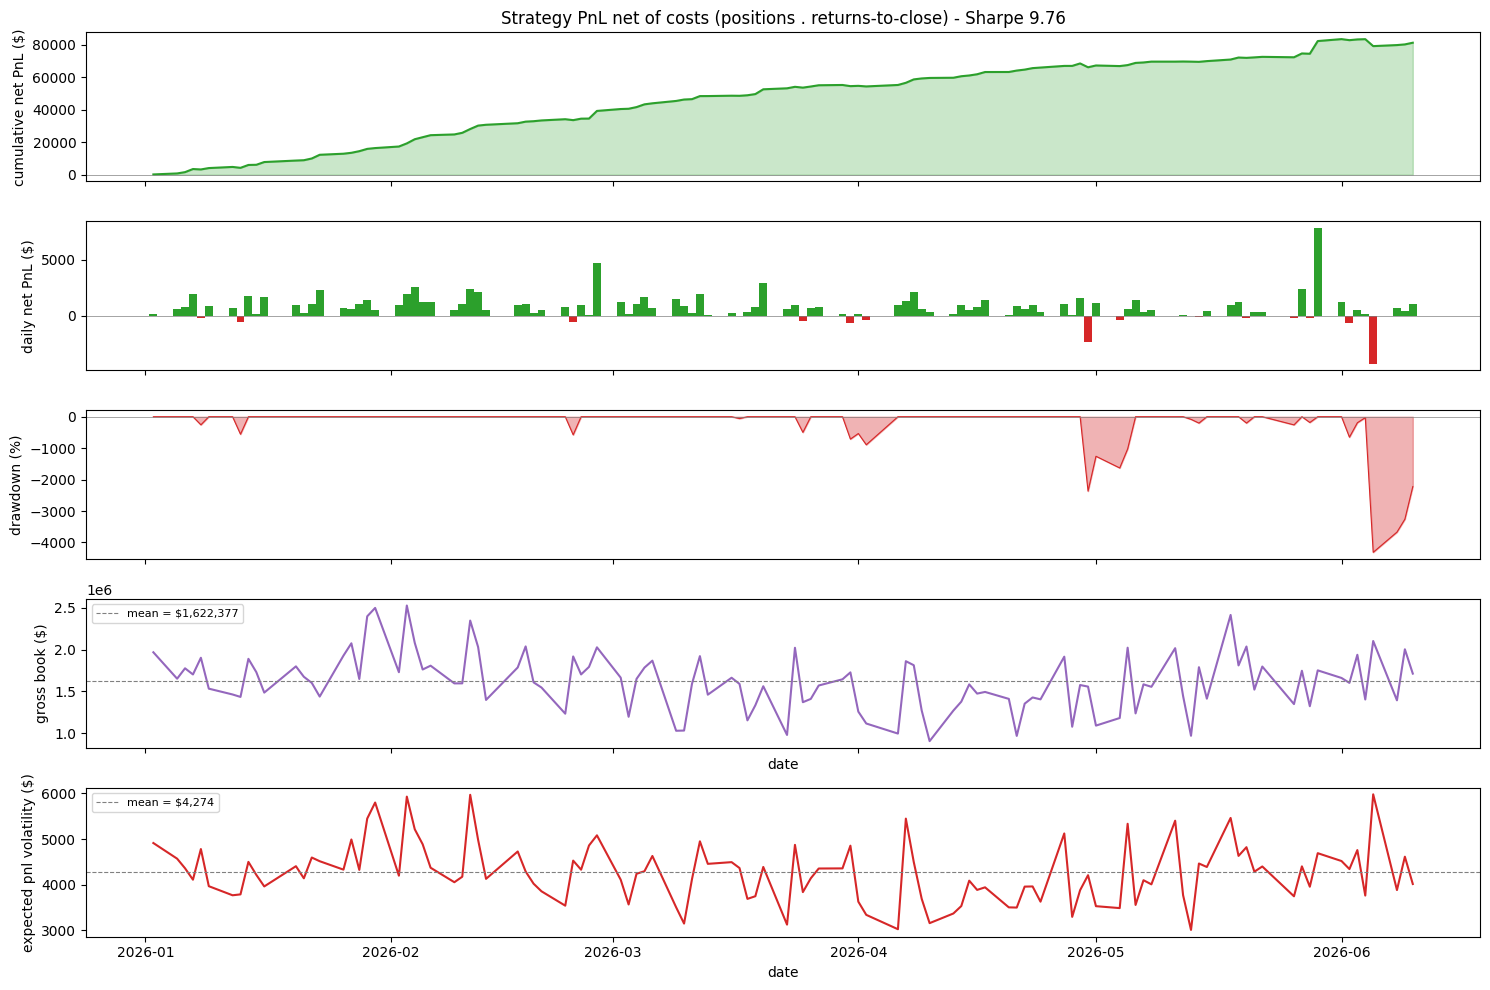

In [22]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (return from entry to the closing auction_i).
# Costs charged as a dot product  |$pos| . cost_rate:
#   - spread:     HALF the quoted spread, ENTRY only (the auction exit has no spread).
#   - commission: $0.0035/share on BOTH legs; spread_return already bundles 0.0035/price (one leg).
#   - impact:     square-root law  gamma * sigma_i * |$pos_i|^{3/2} / sqrt(ADV$_i)  (gamma scalar; sigma_i and
#                 ADV$ are BOTH causal EWMA per-(name,date) columns on test_data).  Same impact the optimizer
#                 trades off: it charges gamma*sqrt(scale)*sum_i sigma_i*|x_i|^{3/2}/sqrt(ADV$_i).
ANN = 252


# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    test_data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"),                        # per-leg commission, as a return
    )
    # spread_return is the pure quoted spread (ask-bid)/mid. Charge half the spread (cross ONCE
    # on entry; the auction exit has no spread) + commission on BOTH legs.
    .with_columns(
        (0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
            .clip(lower_bound=0.0).alias("cost_rate"),
    )
    .with_columns(
        (pl.col("dollar_pos").abs() * pl.col("cost_rate")).alias("cost"),                         # dot product: |$pos| . cost_rate
        (IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()).alias("impact"),  # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
    )
    .with_columns(
        (pl.col("gross_pnl")
         - pl.col("cost")
         - pl.col("impact")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("cost").sum().alias("cost"),
        pl.col("impact").sum().alias("impact"),                # daily sqrt-law impact charge
        pl.col("dollar_pos").abs().sum().alias("GMV"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum_pnl  = pnl_daily["cum_pnl"].to_numpy()
mean_gmv = pnl_daily["GMV"].mean()
median_gmv = pnl_daily["GMV"].median()
rolling_mean_gmv = pnl_daily["GMV"].ewm_mean(alpha=0.06, adjust=True)   
max_gmv = pnl_daily["GMV"].max()
# -- factor decomposition for expected risk --
# √ (xᵀ @ Σ @ x) = √ [ (L @ x)ᵀ @ Σ_𝘍 @ (L @ x) + (xᵀ @ D @ x) ]
exp_vol = [
    np.sqrt(
        np.transpose((L @ np.array([weights[d][s] for s in ACTIVE_SET])))
        @ SIGMA_F
        @ (L @ np.array([weights[d][s] for s in ACTIVE_SET]))
        + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)
    ) for d in weights
]

# Drawdown of the cumulative net-PnL curve (underwater, in $): current - running peak (<= 0).
peak      = np.maximum.accumulate(cum_pnl)
drawdown  = (cum_pnl - peak)
max_dd    = drawdown.min()                          # deepest trough ($, <= 0)

sharpe  = pnl.mean() / pnl.std(ddof=1) * np.sqrt(ANN)

print(f"Days traded:        {len(pnl)}")
print(f"Mean GMV:           ${mean_gmv:,.0f}")
print(f"Median GMV:         ${median_gmv:,.0f}")
print(f"Max GMV:            ${max_gmv:,.0f}  ({max_gmv / mean_gmv:,.1f}x mean GMV)")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total cost:         ${pnl_daily['cost'].sum():,.0f}")
print(f"Total impact:       ${pnl_daily['impact'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Max drawdown:       ${max_dd:,.1f}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gmv = pnl_daily["GMV"].to_numpy()
fig, (ax_pnl, ax_bar, ax_dd, ax_gmv, ax_vol) = plt.subplots(5, 1, figsize=(15, 10), sharex=True, height_ratios=[1, 1, 1, 1, 1])

ax_pnl.plot(dts, cum_pnl, color="tab:green")
ax_pnl.fill_between(dts, cum_pnl, color="tab:green", alpha=0.25)
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.set_ylabel("cumulative net PnL ($)")
ax_pnl.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}")

ax_bar.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax_bar.axhline(0, color="grey", lw=0.5)
ax_bar.set_ylabel("daily net PnL ($)")

# Underwater curve: distance below the running high-water mark of cumulative PnL.
ax_dd.fill_between(dts, drawdown, 0.0, color="tab:red", alpha=0.35)
ax_dd.plot(dts, drawdown, color="tab:red", lw=0.8)
ax_dd.axhline(0, color="grey", lw=0.5)
dd_idx = int(np.argmin(drawdown))
# ax_dd.annotate(f"max DD {max_dd*100:,.1f}%", xy=(dts[dd_idx], max_dd),
#                xytext=(5, 8), textcoords="offset points", fontsize=8, color="tab:red")
ax_dd.set_ylabel("drawdown (%)")

ax_gmv.plot(dts, gmv, color="tab:purple")
ax_gmv.axhline(mean_gmv, color="grey", lw=0.8, ls="--", label=f"mean = ${mean_gmv:,.0f}")
ax_gmv.set_ylabel("gross book ($)")
ax_gmv.set_xlabel("date")
ax_gmv.legend(loc="upper left", fontsize=8)

ax_vol.plot(dts, exp_vol, color="tab:red")
ax_vol.axhline(np.nanmean(exp_vol), color="grey", lw=0.8, ls="--", label=f"mean = ${np.nanmean(exp_vol):,.0f}")
ax_vol.set_ylabel("expected pnl volatility ($)")
ax_vol.set_xlabel("date")
ax_vol.legend(loc="upper left", fontsize=8)
# ax_vol.ticklabel_format(style='plain', axis='y', useOffset=False)


fig.tight_layout()
plt.show()

#### Some diagnostics

In [12]:
ANN = 252
alpha_by_day = {d: a for d, a, _, _ in day_records}      # dense alpha, ACTIVE_SET order
cost_by_day = {d: c for d, _, c, _ in day_records}

exante = []
for d in sorted(weights):
    x = np.array([weights[d][s] for s in ACTIVE_SET])            # $ positions, same order
    a = alpha_by_day[d]                                          # expected returns
    exp_pnl = a @ x - cost_by_day[d] @ np.abs(x)                 # net expected daily $ PnL
    exp_var = (L @ x) @ SIGMA_F @ (L @ x) + np.sum(EPS_DIAG * x**2)   # matches optimizer's risk term
    exante.append(exp_pnl / np.sqrt(exp_var) if exp_var > 0 else np.nan)

exante = np.array(exante)
print(f"Mean expected $vol:   {np.nanmean([np.sqrt(np.transpose((L@np.array([weights[d][s] for s in ACTIVE_SET])))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")
print(f"Max expected $vol:   {np.nanmax([np.sqrt((L@np.array([weights[d][s] for s in ACTIVE_SET]))@SIGMA_F@(L@np.array([weights[d][s] for s in ACTIVE_SET])) + np.sum(EPS_DIAG*np.array([weights[d][s] for s in ACTIVE_SET])**2)) for d in weights]):,.0f}")

Mean expected $vol:   4,217
Max expected $vol:   5,000


In [13]:
from scipy.stats import pearsonr, spearmanr
r, pval = spearmanr(pnl_daily["GMV"], pnl_daily["cum_pnl"])
print(f"Spearman Corr of GMV and PnL: {r:,.5f}")

Spearman Corr of GMV and PnL: -0.23538


### Parameter Sweeps

In [14]:
def _solve_all_weights(lam, vol_cap):
    """Solve every day at (lam, vol_cap); return {date: {symbol: $pos}}."""
    chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
    chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
        delayed(_solve_chunk)(ACTIVE_SET, SIGMA_R, SIGMA_F, L, EPS_DIAG, lam, IMPACT_GAMMA, vol_cap, chunk)
        for chunk in chunks
    )
    return {d: dict(zip(ACTIVE_SET, ws)) for chunk in chunk_results for d, ws in chunk}

def _sweep_point(lam, vol_cap):
    """Solve all days at (lam, vol_cap), then run the SAME net-of-cost + 3/2-power impact
    accounting as the main PnL cell. Returns (mean_gmv, std_gmv, total_net_pnl)."""
    weights_d = _solve_all_weights(lam, vol_cap)
    pos_long = pl.DataFrame({
        "date":       [d for d in weights_d for _ in weights_d[d]],
        "symbol":     [s for d in weights_d for s in weights_d[d]],
        "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))
    pdl = (
        test_data
        .join(pos_long, on=["date", "symbol"], how="inner")
        .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
        .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
        .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
                      .clip(lower_bound=0.0).alias("cost_rate"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("ret_to_close")                 # gross
             - pl.col("dollar_pos").abs() * pl.col("cost_rate")            # spread + commission
             - IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()   # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
             ).alias("net_pnl_name"),
            pl.col("dollar_pos").abs().alias("gmv_name"),
        )
        .group_by("date")
        .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
             pl.col("gmv_name").sum().alias("GMV"))
    )
    gmv = pdl["GMV"].to_numpy()
    return float(gmv.mean()), float(gmv.std()), float(pdl["net_pnl"].sum())

# --- Sweep grids ---
lambda_grid = np.geomspace(1e-9, 1e-5, 100)            # risk aversion per dollar (~ 1/ intended capital)

sweep         = [_sweep_point(lam, 1 * int(1/lam)) for lam in lambda_grid]
gmv_vs_lambda = [(mean, std) for (mean, std, _) in sweep]   # (mean_gmv, std_gmv) — used by the plot cell
pnl_vs_lambda = [pnl for (_, _, pnl) in sweep]              # total net PnL per lambda

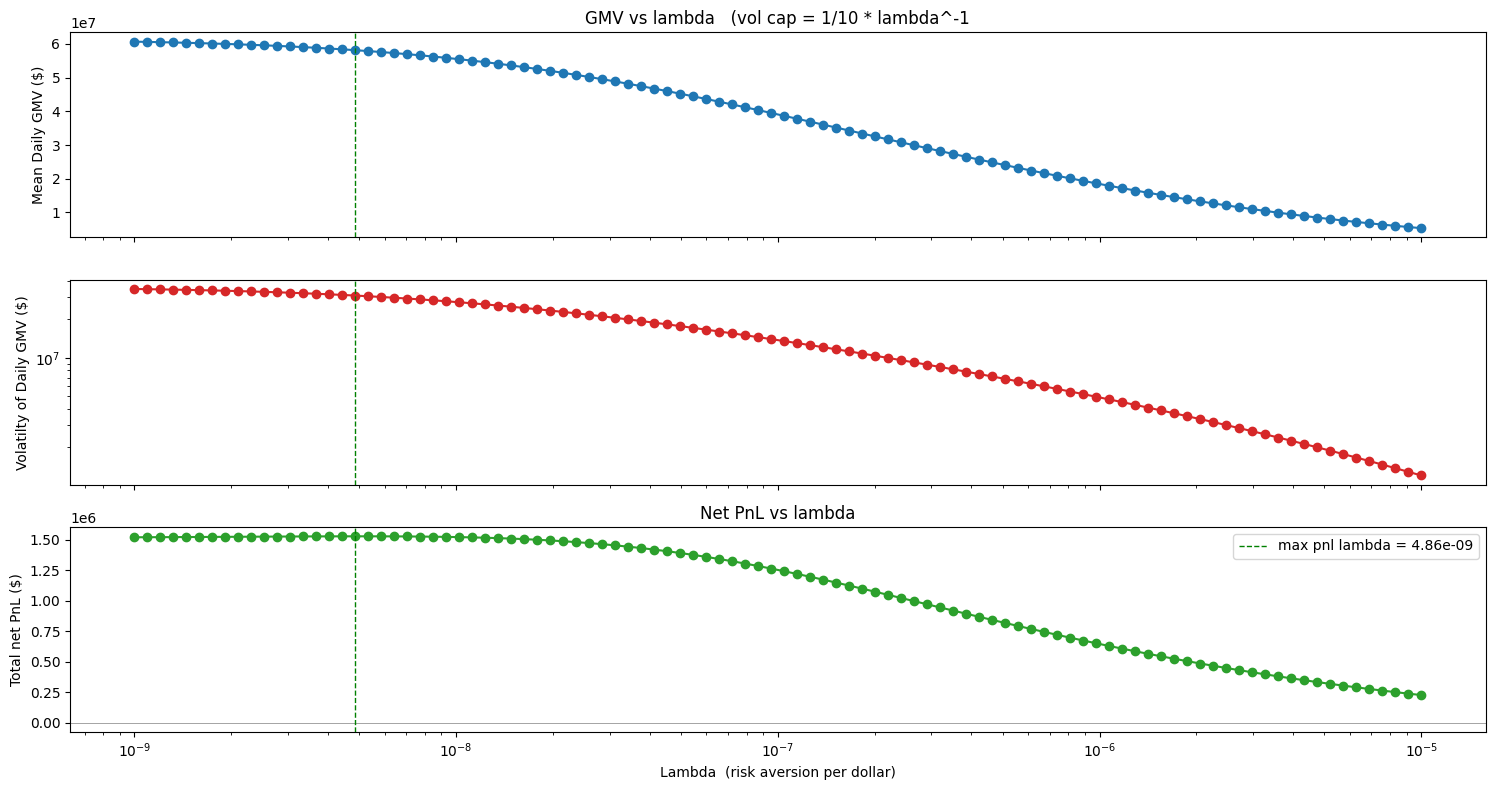

Max PNL:   $1,529,573
GMV:       $58,137,687
*Lambda:   4.86e-09


In [15]:
# --- Plots: GMV + net PnL for each sweep ---
fig, (ax_mean, ax_std, ax_pnl) = plt.subplots(3, 1, figsize=(15, 8), sharex=True)

best_i   = int(np.nanargmax(pnl_vs_lambda))
best_lam = lambda_grid[best_i]
best_gmv = gmv_vs_lambda[best_i][0]
best_pnl = pnl_vs_lambda[best_i]



ax_mean.plot(lambda_grid, [mean for (mean, std) in gmv_vs_lambda], marker="o", color="tab:blue")
ax_mean.axvline(best_lam, color="green", lw=1, linestyle='--', label=f"max pnl lambda = {best_lam:,.2e}")
ax_mean.set_ylabel("Mean Daily GMV ($)")
ax_mean.set_title(f"GMV vs lambda   (vol cap = 1/10 * lambda^-1")

ax_std.plot(lambda_grid, [std for (mean, std) in gmv_vs_lambda], marker="o", color="tab:red")
ax_std.axvline(best_lam, color="green", lw=1, linestyle='--')
ax_std.set_ylabel("Volatilty of Daily GMV ($)")
ax_std.set_xscale("log")
ax_std.set_yscale("log")

# Total net PnL (net of spread, commission, quadratic impact) vs lambda. Linear y: PnL can be < 0.
ax_pnl.plot(lambda_grid, pnl_vs_lambda, marker="o", color="tab:green")
ax_pnl.axhline(0, color="grey", lw=0.5)
ax_pnl.axvline(best_lam, color="green", lw=1, linestyle='--', label=f"max pnl lambda = {best_lam:,.2e}")
ax_pnl.set_xlabel("Lambda  (risk aversion per dollar)")
ax_pnl.set_ylabel("Total net PnL ($)")
ax_pnl.set_title("Net PnL vs lambda")
ax_pnl.set_xscale("log")
ax_pnl.legend()


fig.tight_layout()
plt.show()

print(f"Max PNL:   ${best_pnl:,.0f}")
print(f"GMV:       ${best_gmv:,.0f}"
      f"\n*Lambda:   {best_lam:,.2e}")

### Notes
- For impact (toggled off) are  using a simple gamma which is the coef from regressing 1-second returns on signed dollar volume from 15:50:00 - 16:00:00. This is used in the optimizer to have soe kind of quadratic impact cost, but not in the pnl accounting.
- For our covariance we are using a factor model on causal-voltility-standardized returns. This is for better estimation and numerical sparsity. We then use a sample volatility value (with a floor) to get the model back into return units.
- We improved the forecast by using Lasso(alpha=1e-4) with multiple features and interaction terms.

### Next:
- We need a way to account for impact in the accounting? This would give us a better idea of capacity. For now, our estimate of capacity is the lowest GMV for which net pnl is approximately at the cap (check parameter sweeps with impact turned on.)
        - This is the maximum the optimizer is willing to send GMV. Is is not directly dependent on real PNL, since the impact isn't actually accounted for.
- More issues with universe. Some things are in ACTIVE_SET but not UNIVERSE. The universe is fixed adn used throughout. Does not account for renaming.
- What we should be doing is using a rolling/walking universe of the top N **equities** (not etfs, etc.) by ADV/MDV and reconstructing the forecast, covariance, and impact models for each period.

In [16]:
# ===== 2-D parameter sweep: lambda x volatility cap =====
# For each (lambda, vol_cap) on the grid, solve every day and run the SAME net-of-cost +
# 3/2-power impact accounting as the main PnL cell. Records mean daily GMV, total net PnL,
# and annualized Sharpe at each node. Unlike the 1-D sweep above, lambda and the vol cap are
# swept INDEPENDENTLY (not tied on a ray). Reuses _solve_all_weights from the
# 1-D sweep cell above — run that cell first.
ANN = 252

def _grid_point(lam, vol_cap):
    """Solve all days at (lam, vol_cap); return (mean_gmv, total_net_pnl, sharpe)."""
    weights_d = _solve_all_weights(lam, vol_cap)
    pos_long = pl.DataFrame({
        "date":       [d for d in weights_d for _ in weights_d[d]],
        "symbol":     [s for d in weights_d for s in weights_d[d]],
        "dollar_pos": [w for d in weights_d for w in weights_d[d].values()],
    }).with_columns(pl.col("symbol").cast(pl.Categorical))
    pdl = (
        test_data
        .join(pos_long, on=["date", "symbol"], how="inner")
        .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
        .with_columns((COMMISSION_PER_SHARE / pl.col("entry_price")).alias("comm_rate"))
        .with_columns((0.5 * pl.col("spread_return") + 2.0 * pl.col("comm_rate"))
                      .clip(lower_bound=0.0).alias("cost_rate"))
        .with_columns(
            (pl.col("dollar_pos") * pl.col("ret_to_close")                 # gross
             - pl.col("dollar_pos").abs() * pl.col("cost_rate")            # spread + commission
             - IMPACT_GAMMA * pl.col("vol") * pl.col("dollar_pos").abs() ** 1.5 / pl.col("ADV").sqrt()   # gamma*sigma_i*|Q$|^{3/2}/sqrt(ADV$)
             ).alias("net_pnl_name"),
            pl.col("dollar_pos").abs().alias("gmv_name"),
        )
        .group_by("date")
        .agg(pl.col("net_pnl_name").sum().alias("net_pnl"),
             pl.col("gmv_name").sum().alias("GMV"))
    )
    pnl = pdl["net_pnl"].to_numpy()
    sd  = pnl.std(ddof=1)
    return (float(pdl["GMV"].mean()),
            float(pnl.sum()),
            float(pnl.mean() / sd * np.sqrt(ANN)) if sd > 0 else np.nan)

# --- Grid axes (edit ranges/resolution to taste; cost ~ n_lam * n_volcap full solves) ---
lam_grid    = np.geomspace(1e-9, 1e-5, 25)     # risk aversion per dollar
volcap_grid = np.geomspace(1e4, 1e8, 25)       # target daily $ volatility cap

# Surfaces, shape (n_volcap, n_lambda): rows = vol cap, cols = lambda.
GMV_grid    = np.full((len(volcap_grid), len(lam_grid)), np.nan)
PNL_grid    = np.full((len(volcap_grid), len(lam_grid)), np.nan)
SHARPE_grid = np.full((len(volcap_grid), len(lam_grid)), np.nan)
for i, vc in enumerate(volcap_grid):
    for j, lam in enumerate(lam_grid):
        GMV_grid[i, j], PNL_grid[i, j], SHARPE_grid[i, j] = _grid_point(lam, vc)
    print(f"vol cap {vc:.1e} done ({i + 1}/{len(volcap_grid)})")

# --- Argmax over total net PnL: report lambda / vol cap / GMV / Sharpe there ---
best_i, best_j = np.unravel_index(np.nanargmax(PNL_grid), PNL_grid.shape)
best = {
    "lambda":  float(lam_grid[best_j]),
    "vol_cap": float(volcap_grid[best_i]),
    "gmv":     float(GMV_grid[best_i, best_j]),
    "pnl":     float(PNL_grid[best_i, best_j]),
    "sharpe":  float(SHARPE_grid[best_i, best_j]),
}
print(f"\nMax net PnL ${best['pnl']:,.0f} at "
      f"lambda={best['lambda']:.3e}, vol_cap={best['vol_cap']:.3e} "
      f"(mean GMV ${best['gmv']:,.0f}, Sharpe {best['sharpe']:.2f})")
best

vol cap 1.0e+04 done (1/25)
vol cap 1.5e+04 done (2/25)
vol cap 2.2e+04 done (3/25)
vol cap 3.2e+04 done (4/25)
vol cap 4.6e+04 done (5/25)
vol cap 6.8e+04 done (6/25)
vol cap 1.0e+05 done (7/25)
vol cap 1.5e+05 done (8/25)
vol cap 2.2e+05 done (9/25)
vol cap 3.2e+05 done (10/25)
vol cap 4.6e+05 done (11/25)
vol cap 6.8e+05 done (12/25)
vol cap 1.0e+06 done (13/25)
vol cap 1.5e+06 done (14/25)
vol cap 2.2e+06 done (15/25)
vol cap 3.2e+06 done (16/25)
vol cap 4.6e+06 done (17/25)
vol cap 6.8e+06 done (18/25)
vol cap 1.0e+07 done (19/25)
vol cap 1.5e+07 done (20/25)
vol cap 2.2e+07 done (21/25)
vol cap 3.2e+07 done (22/25)
vol cap 4.6e+07 done (23/25)
vol cap 6.8e+07 done (24/25)
vol cap 1.0e+08 done (25/25)

Max net PnL $1,552,506 at lambda=3.162e-09, vol_cap=1.468e+06 (mean GMV $58,964,913, Sharpe 1.94)


{'lambda': 3.1622776601683795e-09,
 'vol_cap': 1467799.2676220676,
 'gmv': 58964912.54834799,
 'pnl': 1552506.0707689794,
 'sharpe': 1.9380354031619633}

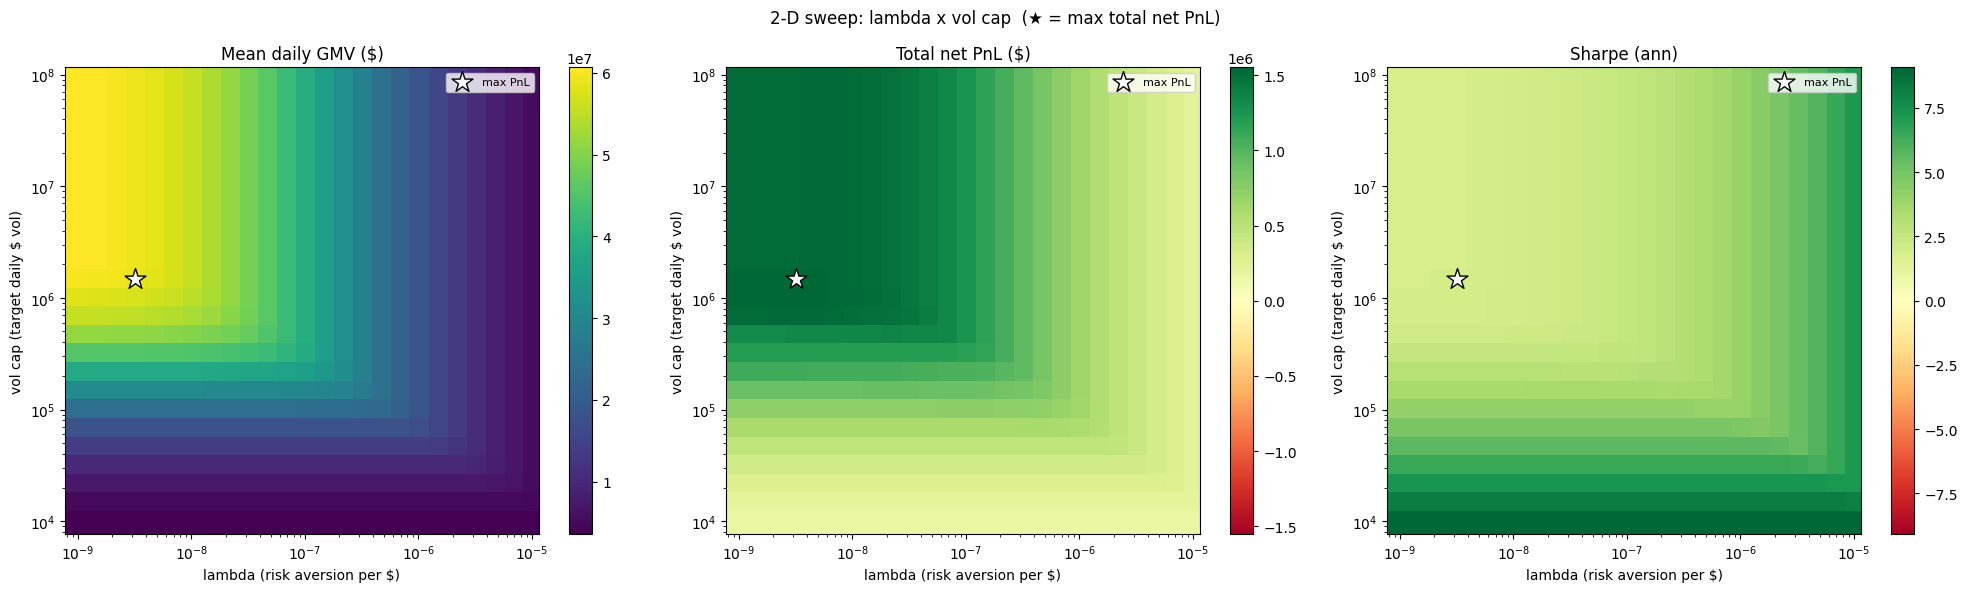

Max total net PnL: $1,552,506
  lambda:   3.162e-09
  vol cap:  1.468e+06
  mean GMV: $58,964,913
  Sharpe:   1.94


In [17]:
# --- Plots: GMV / net PnL / Sharpe surfaces over the (lambda, vol_cap) grid ---
def _heat(ax, Z, title, cmap, diverging=False):
    kw = {}
    if diverging:
        v = float(np.nanmax(np.abs(Z)))
        kw = {"vmin": -v, "vmax": v}            # center the diverging map at 0
    pcm = ax.pcolormesh(lam_grid, volcap_grid, Z, shading="nearest", cmap=cmap, **kw)
    fig.colorbar(pcm, ax=ax)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("lambda (risk aversion per $)")
    ax.set_ylabel("vol cap (target daily $ vol)")
    ax.set_title(title)
    ax.scatter([best["lambda"]], [best["vol_cap"]], marker="*", s=250,
               color="white", edgecolor="black", zorder=5, label="max PnL")
    ax.legend(loc="upper right", fontsize=8)

fig, (ax_g, ax_p, ax_s) = plt.subplots(1, 3, figsize=(20, 6))
_heat(ax_g, GMV_grid,    "Mean daily GMV ($)", "viridis")
_heat(ax_p, PNL_grid,    "Total net PnL ($)",  "RdYlGn", diverging=True)
_heat(ax_s, SHARPE_grid, "Sharpe (ann)",       "RdYlGn", diverging=True)

fig.suptitle("2-D sweep: lambda x vol cap  (★ = max total net PnL)")
fig.tight_layout()
plt.show()

print(f"Max total net PnL: ${best['pnl']:,.0f}")
print(f"  lambda:   {best['lambda']:.3e}")
print(f"  vol cap:  {best['vol_cap']:.3e}")
print(f"  mean GMV: ${best['gmv']:,.0f}")
print(f"  Sharpe:   {best['sharpe']:.2f}")